In [65]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

### Dataset Loading and understanding

In [29]:
# Load original dataset
df_original = pd.read_csv("application_train.csv")

print("Original dataset:", df_original.shape)

# Take a stratified 10% sample
df = (
    df_original.groupby("TARGET", group_keys=False)
    .sample(frac=0.10, random_state=42)
    .reset_index(drop=True)
)

print("Reduced dataset:", df.shape)

Original dataset: (307511, 122)
Reduced dataset: (30751, 122)


In [30]:
selected_columns = [
    "TARGET",
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "CNT_CHILDREN",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CNT_FAM_MEMBERS",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

df = df[selected_columns].copy()

print("Final dataset shape:", df.shape)
df.head()

Final dataset shape: (30751, 18)


,TARGET,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS,EXT_SOURCE_2,EXT_SOURCE_3
0,0,M,Y,Y,1,292500.0,1102500.0,32364.0,1102500.0,Working,Secondary / secondary special,Married,House / apartment,-11763,-688,3.0,0.616187,0.651260
1,0,F,N,Y,0,270000.0,720000.0,36000.0,720000.0,Pensioner,Incomplete higher,Married,House / apartment,-23199,365243,2.0,0.728499,0.638044
2,0,F,Y,Y,1,135000.0,360000.0,18000.0,360000.0,Working,Higher education,Widow,House / apartment,-19165,-3432,2.0,0.667953,0.108226
3,0,F,Y,N,0,90000.0,225000.0,10426.5,225000.0,Commercial associate,Secondary / secondary special,Single / not married,With parents,-10416,-1154,1.0,0.295033,0.194068
4,0,F,N,N,0,283500.0,1800000.0,51718.5,1800000.0,Commercial associate,Higher education,Married,House / apartment,-12125,-3256,2.0,0.662894,0.441836


In [31]:
df.shape

(30751, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30751 entries, 0 to 30750
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   TARGET               30751 non-null  int64  
 1   CODE_GENDER          30751 non-null  object 
 2   FLAG_OWN_CAR         30751 non-null  object 
 3   FLAG_OWN_REALTY      30751 non-null  object 
 4   CNT_CHILDREN         30751 non-null  int64  
 5   AMT_INCOME_TOTAL     30751 non-null  float64
 6   AMT_CREDIT           30751 non-null  float64
 7   AMT_ANNUITY          30748 non-null  float64
 8   AMT_GOODS_PRICE      30736 non-null  float64
 9   NAME_INCOME_TYPE     30751 non-null  object 
 10  NAME_EDUCATION_TYPE  30751 non-null  object 
 11  NAME_FAMILY_STATUS   30751 non-null  object 
 12  NAME_HOUSING_TYPE    30751 non-null  object 
 13  DAYS_BIRTH           30751 non-null  int64  
 14  DAYS_EMPLOYED        30751 non-null  int64  
 15  CNT_FAM_MEMBERS      30751 non-null 

In [6]:
df.describe()

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS,EXT_SOURCE_2,EXT_SOURCE_3
count,30751.000000,30751.000000,3.075100e+04,3.075100e+04,30748.000000,3.073600e+04,30751.000000,30751.000000,30751.000000,30689.000000,24612.000000
mean,0.080713,0.419466,1.677632e+05,5.997481e+05,27141.455395,5.393350e+05,-16002.559819,63858.539560,2.154792,0.515179,0.510887
std,0.272398,0.730571,9.455113e+04,4.023007e+05,14526.626590,3.693767e+05,4364.838215,141313.455633,0.917494,0.190135,0.194198
min,0.000000,0.000000,2.700000e+04,4.500000e+04,2205.000000,4.500000e+04,-25180.000000,-17546.000000,1.000000,0.000010,0.000527
25%,0.000000,0.000000,1.125000e+05,2.700000e+05,16492.500000,2.385000e+05,-19656.500000,-2758.000000,2.000000,0.394733,0.370650
50%,0.000000,0.000000,1.440000e+05,5.175000e+05,25042.500000,4.500000e+05,-15699.000000,-1221.000000,2.000000,0.566907,0.535276
75%,0.000000,1.000000,2.025000e+05,8.086500e+05,34650.000000,6.795000e+05,-12361.500000,-298.000000,3.000000,0.662396,0.667458
max,1.000000,19.000000,2.250000e+06,3.312162e+06,225000.000000,3.150000e+06,-7673.000000,365243.000000,20.000000,0.855000,0.885488


In [7]:
df.describe(include="object")

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE
count,30751,30751,30751,30751,30751,30751,30751
unique,3,2,2,8,5,5,6
top,F,N,Y,Working,Secondary / secondary special,Married,House / apartment
freq,20244,20349,21375,15733,21698,19661,27214


In [8]:
df["TARGET"].value_counts()

TARGET
0    28269
1     2482
Name: count, dtype: int64

In [9]:
df["TARGET"].value_counts(normalize=True) * 100

TARGET
0    91.928718
1     8.071282
Name: proportion, dtype: float64

In [12]:
df.duplicated().sum()

np.int64(0)

In [8]:
# Check missing values in selected features
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
EXT_SOURCE_3,6139,19.963578
EXT_SOURCE_2,62,0.201619
AMT_GOODS_PRICE,15,0.048779
AMT_ANNUITY,3,0.009756
NAME_EDUCATION_TYPE,0,0.000000
CNT_FAM_MEMBERS,0,0.000000
DAYS_EMPLOYED,0,0.000000
DAYS_BIRTH,0,0.000000
NAME_HOUSING_TYPE,0,0.000000
NAME_FAMILY_STATUS,0,0.000000


In [ ]:
# Check unique values in categorical features
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


CODE_GENDER:
CODE_GENDER
F      20244
M      10506
XNA        1
Name: count, dtype: int64

FLAG_OWN_CAR:
FLAG_OWN_CAR
N    20349
Y    10402
Name: count, dtype: int64

FLAG_OWN_REALTY:
FLAG_OWN_REALTY
Y    21375
N     9376
Name: count, dtype: int64

NAME_INCOME_TYPE:
NAME_INCOME_TYPE
Working                 15733
Commercial associate     7206
Pensioner                5540
State servant            2266
Student                     3
Unemployed                  1
Maternity leave             1
Businessman                 1
Name: count, dtype: int64

NAME_EDUCATION_TYPE:
NAME_EDUCATION_TYPE
Secondary / secondary special    21698
Higher education                  7561
Incomplete higher                 1089
Lower secondary                    391
Academic degree                     12
Name: count, dtype: int64

NAME_FAMILY_STATUS:
NAME_FAMILY_STATUS
Married                 19661
Single / not married     4497
Civil marriage           2951
Separated                2025
Widow                    1

In [10]:
# Check unusual employment values
print("DAYS_EMPLOYED value counts:")
print(df["DAYS_EMPLOYED"].value_counts().head(10))

print("\nMaximum DAYS_EMPLOYED:")
print(df["DAYS_EMPLOYED"].max())

DAYS_EMPLOYED value counts:
DAYS_EMPLOYED
 365243    5541
-188         21
-231         21
-224         20
-209         20
-199         20
-215         19
-1021        19
-384         19
-216         19
Name: count, dtype: int64

Maximum DAYS_EMPLOYED:
365243


data cleaning

In [33]:
# Replace the employment placeholder with missing values
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

# Verify the replacement
print("Missing DAYS_EMPLOYED values:", df["DAYS_EMPLOYED"].isnull().sum())

Missing DAYS_EMPLOYED values: 5541


### Exploratory Data Analysis

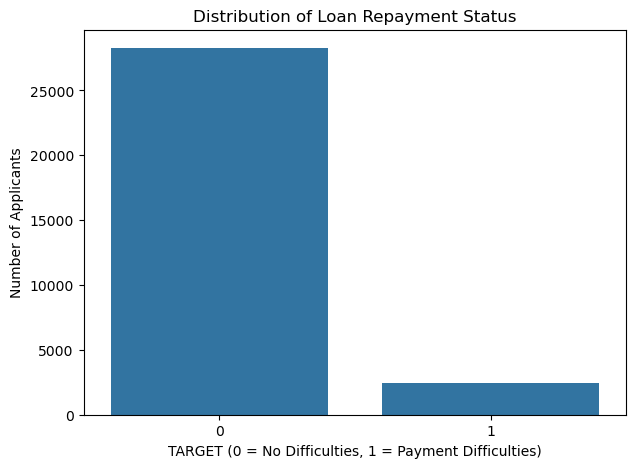

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="TARGET")

plt.title("Distribution of Loan Repayment Status")
plt.xlabel("TARGET (0 = No Difficulties, 1 = Payment Difficulties)")
plt.ylabel("Number of Applicants")

plt.show()

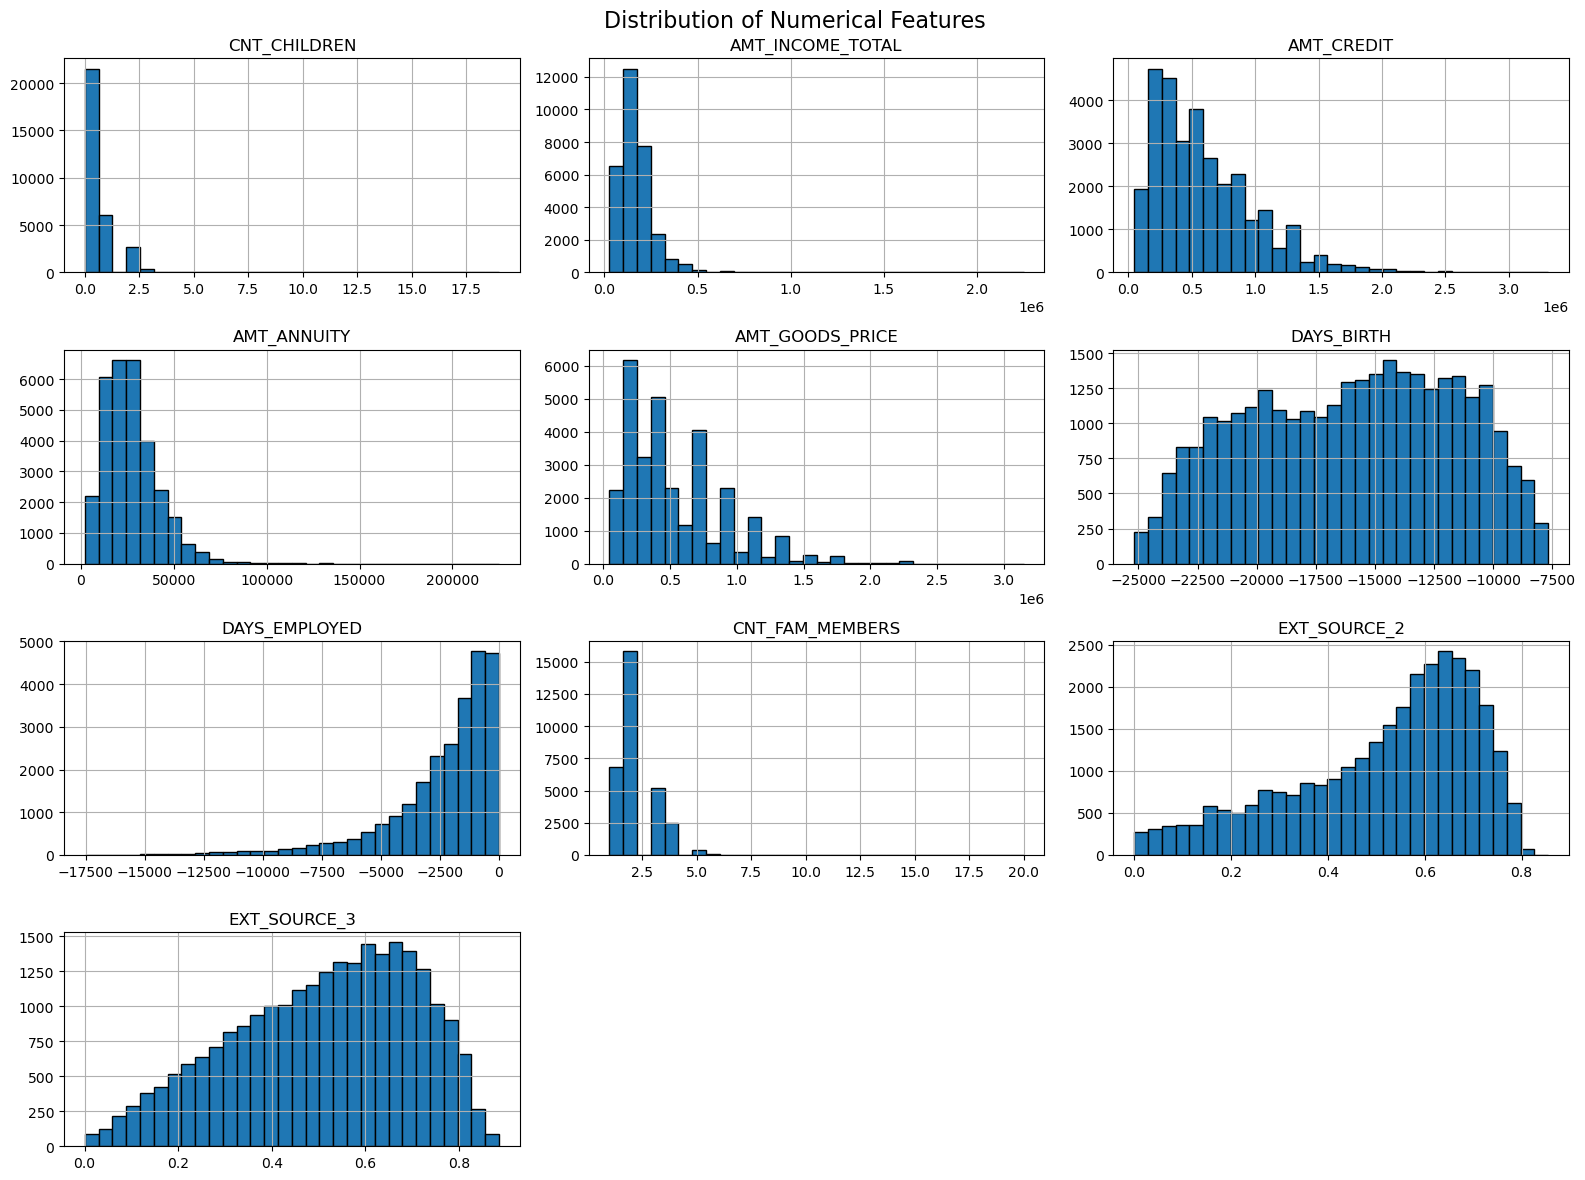

In [15]:
# Select numerical columns
numerical_columns = [
    "CNT_CHILDREN",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CNT_FAM_MEMBERS",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

# Plot distributions
df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

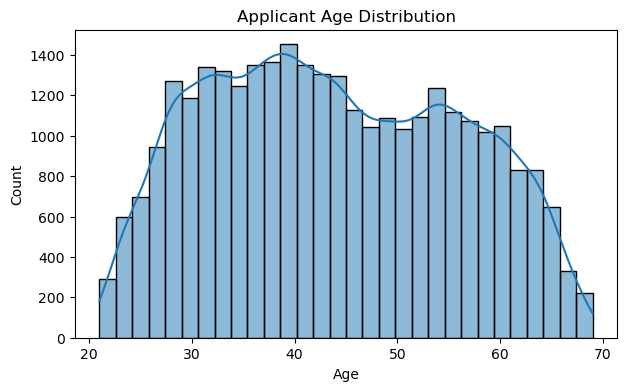

In [15]:
df["AGE"] = abs(df["DAYS_BIRTH"]) / 365

plt.figure(figsize=(7, 4))

sns.histplot(df["AGE"], bins=30, kde=True)

plt.title("Applicant Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

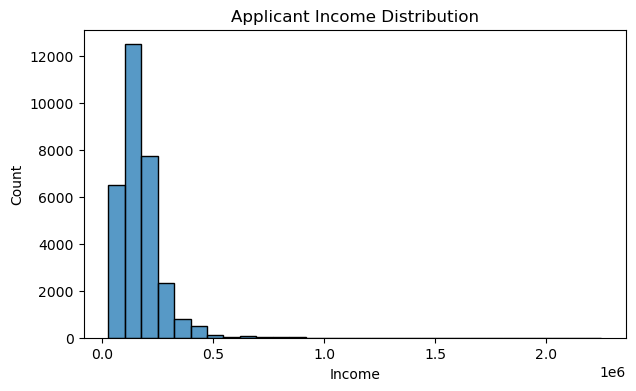

In [16]:
plt.figure(figsize=(7, 4))

sns.histplot(df["AMT_INCOME_TOTAL"], bins=30)

plt.title("Applicant Income Distribution")
plt.xlabel("Income")
plt.ylabel("Count")

plt.show()

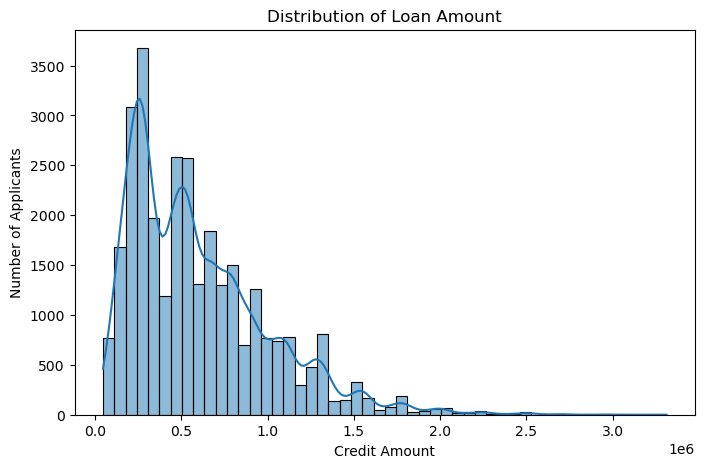

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(df["AMT_CREDIT"], bins=50, kde=True)

plt.title("Distribution of Loan Amount")
plt.xlabel("Credit Amount")
plt.ylabel("Number of Applicants")

plt.show()

<Figure size 400x200 with 0 Axes>

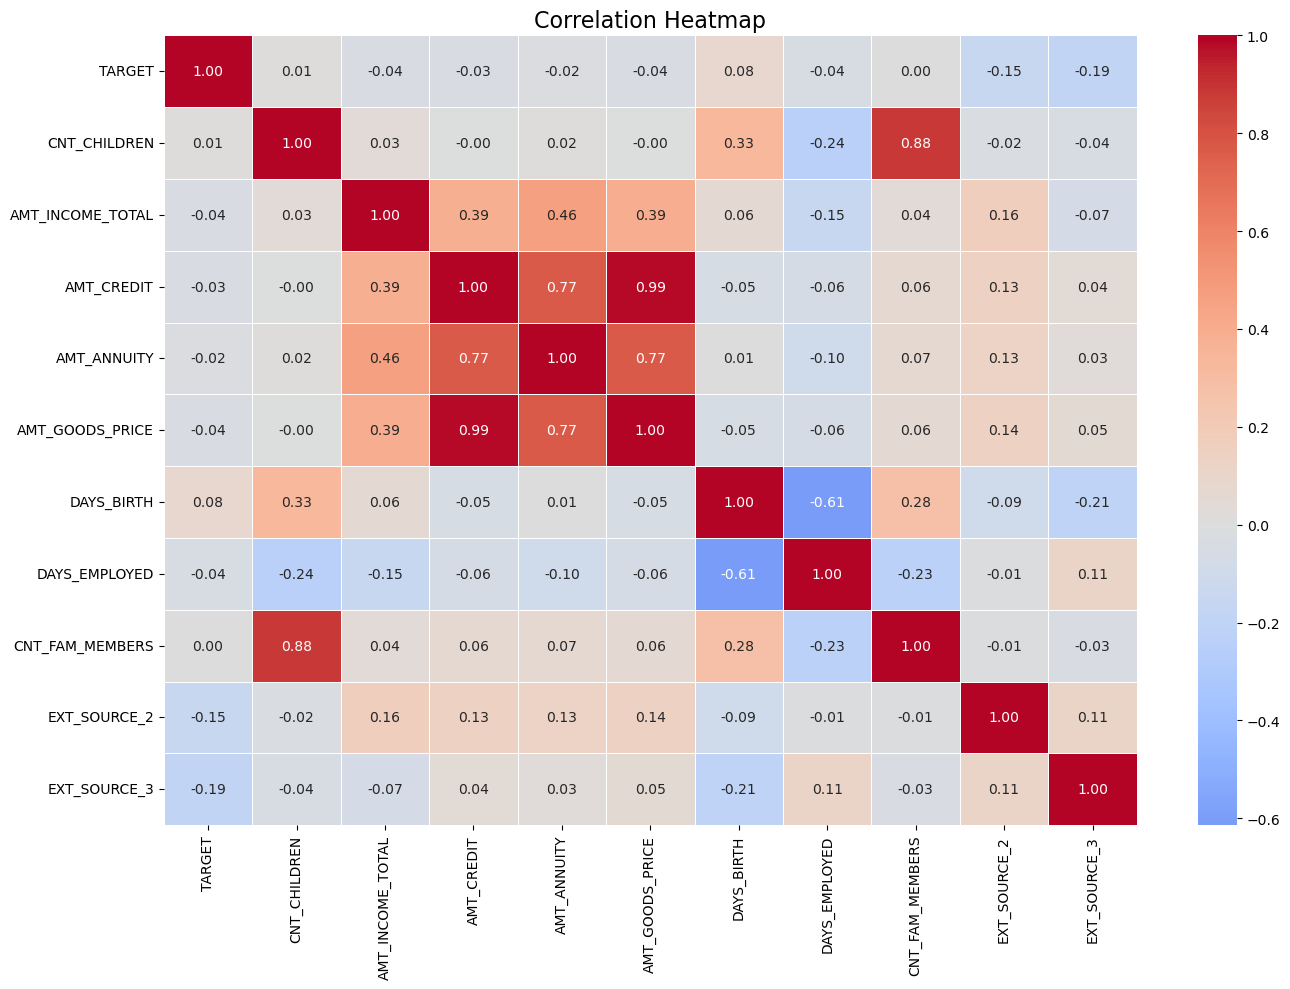

In [7]:
plt.figure(figsize=(4, 2))

# Select numerical columns before feature engineering
numerical_data = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Plot correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

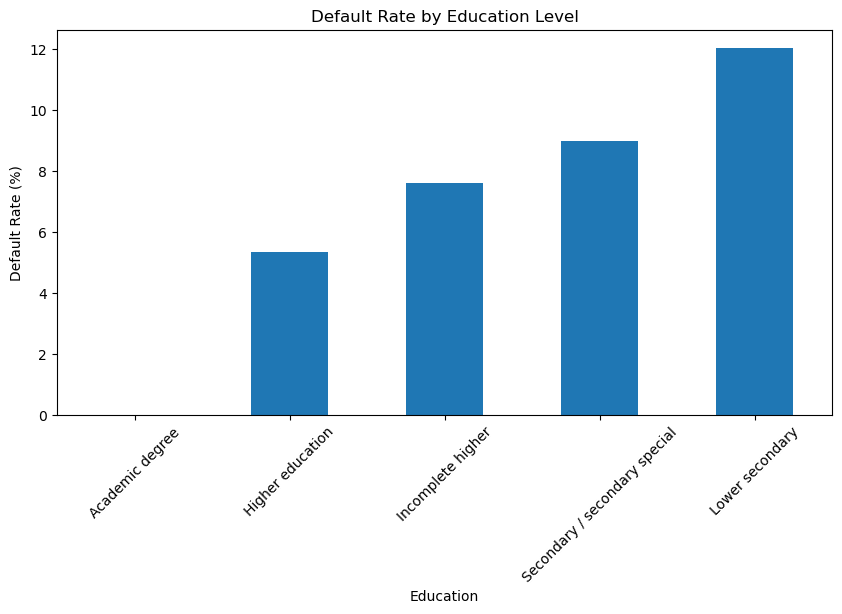

In [18]:
education_default = df.groupby("NAME_EDUCATION_TYPE")["TARGET"].mean() * 100

education_default.sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Default Rate by Education Level")
plt.xlabel("Education")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

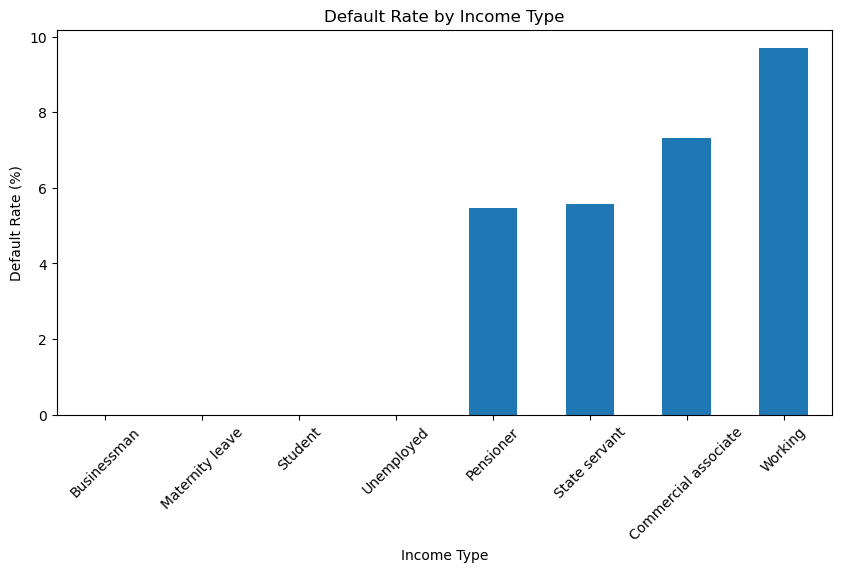

In [19]:
income_default = df.groupby("NAME_INCOME_TYPE")["TARGET"].mean() * 100

income_default.sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Default Rate by Income Type")
plt.xlabel("Income Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

plt.show()

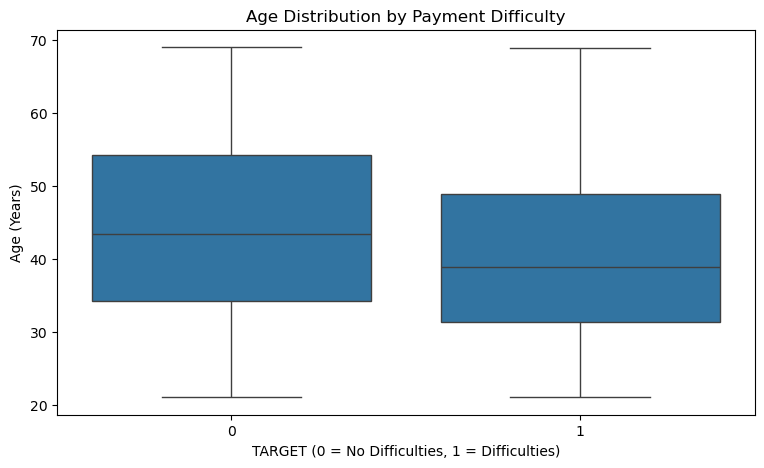

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="TARGET", y="AGE")

plt.title("Age Distribution by Payment Difficulty")
plt.xlabel("TARGET (0 = No Difficulties, 1 = Difficulties)")
plt.ylabel("Age (Years)")

plt.show()

### Feature Engineering

In [34]:
df["AGE"] = (df["DAYS_BIRTH"].abs() / 365).round(1)

df[["DAYS_BIRTH", "AGE"]].head()

,DAYS_BIRTH,AGE
0,-11763,32.2
1,-23199,63.6
2,-19165,52.5
3,-10416,28.5
4,-12125,33.2


In [35]:
df["EMPLOYMENT_YEARS"] = (
    df["DAYS_EMPLOYED"].abs() / 365
).round(1)

In [36]:
df["CREDIT_INCOME_RATIO"] = (
    df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
).round(2)

df[["AMT_CREDIT", "AMT_INCOME_TOTAL", "CREDIT_INCOME_RATIO"]].head()

,AMT_CREDIT,AMT_INCOME_TOTAL,CREDIT_INCOME_RATIO
0,1102500.0,292500.0,3.77
1,720000.0,270000.0,2.67
2,360000.0,135000.0,2.67
3,225000.0,90000.0,2.50
4,1800000.0,283500.0,6.35


In [37]:
df["ANNUITY_INCOME_RATIO"] = (
    df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
).round(3)

df[["AMT_ANNUITY", "AMT_INCOME_TOTAL", "ANNUITY_INCOME_RATIO"]].head()

,AMT_ANNUITY,AMT_INCOME_TOTAL,ANNUITY_INCOME_RATIO
0,32364.0,292500.0,0.111
1,36000.0,270000.0,0.133
2,18000.0,135000.0,0.133
3,10426.5,90000.0,0.116
4,51718.5,283500.0,0.182


In [38]:
df["CREDIT_ANNUITY_RATIO"] = (
    df["AMT_CREDIT"] / df["AMT_ANNUITY"]
).round(2)

df[["AMT_CREDIT", "AMT_ANNUITY", "CREDIT_ANNUITY_RATIO"]].head()

,AMT_CREDIT,AMT_ANNUITY,CREDIT_ANNUITY_RATIO
0,1102500.0,32364.0,34.07
1,720000.0,36000.0,20.00
2,360000.0,18000.0,20.00
3,225000.0,10426.5,21.58
4,1800000.0,51718.5,34.80


In [39]:
new_features = [
    "AGE",
    "EMPLOYMENT_YEARS",
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_ANNUITY_RATIO"
]

print("New features:", len(new_features))
print(df[new_features].head())
print("\nDataset shape:", df.shape)

New features: 5
    AGE  EMPLOYMENT_YEARS  CREDIT_INCOME_RATIO  ANNUITY_INCOME_RATIO  \
0  32.2               1.9                 3.77                 0.111   
1  63.6               NaN                 2.67                 0.133   
2  52.5               9.4                 2.67                 0.133   
3  28.5               3.2                 2.50                 0.116   
4  33.2               8.9                 6.35                 0.182   

   CREDIT_ANNUITY_RATIO  
0                 34.07  
1                 20.00  
2                 20.00  
3                 21.58  
4                 34.80  

Dataset shape: (30751, 23)


In [41]:
df.drop(columns=["DAYS_BIRTH"], inplace=True)

print("Updated dataset shape:", df.shape)

Updated dataset shape: (30751, 22)


In [42]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTarget distribution:")
print(df["TARGET"].value_counts(normalize=True) * 100)

Dataset shape: (30751, 22)

Missing values:
AMT_ANNUITY                3
AMT_GOODS_PRICE           15
DAYS_EMPLOYED           5541
EXT_SOURCE_2              62
EXT_SOURCE_3            6139
EMPLOYMENT_YEARS        5541
ANNUITY_INCOME_RATIO       3
CREDIT_ANNUITY_RATIO       3
dtype: int64

Target distribution:
TARGET
0    91.928718
1     8.071282
Name: proportion, dtype: float64


### Data Preprocessing

In [43]:
X = df.drop("TARGET", axis=1)
y = df["TARGET"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30751, 21)
y shape: (30751,)


In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (24600, 21)
Testing features: (6151, 21)

Training target distribution:
TARGET
0    91.926829
1     8.073171
Name: proportion, dtype: float64

Testing target distribution:
TARGET
0    91.936271
1     8.063729
Name: proportion, dtype: float64


In [45]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 14
['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE', 'EMPLOYMENT_YEARS', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'CREDIT_ANNUITY_RATIO']

Categorical features: 7
['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE']


In [46]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [47]:
# Fit on training data and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (24600, 44)
Processed testing shape: (6151, 44)


### Feature Selection

In [48]:
print("Features before encoding:", X_train.shape[1])
print("Features after encoding:", X_train_processed.shape[1])

Features before encoding: 21
Features after encoding: 44


In [49]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=30)

X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train
)

print("Original feature count:", X_train_processed.shape[1])
print("Selected feature count:", X_train_selected.shape[1])

Original feature count: 44
Selected feature count: 30


In [50]:
print("Training target counts:")
print(y_train.value_counts())

print("\nTraining target percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training target counts:
TARGET
0    22614
1     1986
Name: count, dtype: int64

Training target percentages:
TARGET
0    91.926829
1     8.073171
Name: proportion, dtype: float64


### Model Training

In [54]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation is ready!")

5-Fold Stratified Cross-Validation is ready!


In [55]:
from sklearn.pipeline import Pipeline

def create_model_pipeline(model):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("feature_selection", SelectKBest(
            score_func=f_classif,
            k=30
        )),
        ("classifier", model)
    ])

print("Baseline model pipeline function created!")

Baseline model pipeline function created!


In [59]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "AdaBoost": AdaBoostClassifier(
        random_state=42
    ),

    "Naive Bayes": GaussianNB()
}

print("Total algorithms:", len(models))

Total algorithms: 8


In [ ]:
from sklearn.model_selection import cross_validate
import pandas as pd

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

baseline_results = []

for name, model in models.items():

    print(f"Training {name}...")

    pipeline = create_model_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    baseline_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

baseline_df = pd.DataFrame(baseline_results)

baseline_df = baseline_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(baseline_df.round(4))

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training XGBoost...
Training KNN...
Training AdaBoost...
Training Naive Bayes...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
7,Naive Bayes,0.8406,0.1897,0.2976,0.2316,0.6787
1,Decision Tree,0.8538,0.1504,0.1747,0.1616,0.5441
4,XGBoost,0.9133,0.3141,0.0609,0.1018,0.6978
5,KNN,0.9135,0.2920,0.0493,0.0843,0.5987
3,Gradient Boosting,0.9186,0.4221,0.0232,0.0439,0.7457
0,Logistic Regression,0.9192,0.5071,0.0136,0.0264,0.7400
2,Random Forest,0.9194,0.6433,0.0060,0.0119,0.7074
6,AdaBoost,0.9190,0.4524,0.0045,0.0090,0.7325


In [63]:
weighted_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=42, n_jobs=-1
    )
}

In [64]:
weighted_results = []

for name, model in weighted_models.items():

    print(f"Training {name} with class weighting...")

    pipeline = create_model_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    weighted_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

weighted_df = pd.DataFrame(weighted_results)

display(weighted_df.round(4))

Training Logistic Regression with class weighting...
Training Decision Tree with class weighting...
Training Random Forest with class weighting...


c:\Users\fathi\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6890,0.1604,0.6732,0.2591,0.7400
1,Decision Tree,0.8609,0.1436,0.1455,0.1445,0.5346
2,Random Forest,0.9191,0.2833,0.0030,0.0060,0.7138


In [66]:
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

sample_weighted_models = {
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

sample_weighted_results = []

for name, model in sample_weighted_models.items():

    print(f"Training {name} with sample weights...")

    fold_metrics = []

    for train_idx, val_idx in cv.split(X_train, y_train):

        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        pipeline = create_model_pipeline(clone(model))

        weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        pipeline.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=weights
        )

        y_pred = pipeline.predict(X_fold_val)
        y_prob = pipeline.predict_proba(X_fold_val)[:, 1]

        fold_metrics.append({
            "Accuracy": accuracy_score(y_fold_val, y_pred),
            "Precision": precision_score(y_fold_val, y_pred, zero_division=0),
            "Recall": recall_score(y_fold_val, y_pred, zero_division=0),
            "F1 Score": f1_score(y_fold_val, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_fold_val, y_prob)
        })

    result = pd.DataFrame(fold_metrics).mean()

    sample_weighted_results.append({
        "Model": name,
        **result.to_dict()
    })

sample_weighted_df = pd.DataFrame(sample_weighted_results)

display(sample_weighted_df.round(4))

Training Gradient Boosting with sample weights...
Training AdaBoost with sample weights...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.7187,0.1682,0.6289,0.2654,0.7419
1,AdaBoost,0.6829,0.1554,0.6586,0.2514,0.7325


In [67]:
xgb_weighted = XGBClassifier(
    n_estimators=200,
    scale_pos_weight=11.39,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

In [68]:
xgb_pipeline = create_model_pipeline(xgb_weighted)

xgb_scores = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=1
)

xgb_weighted_df = pd.DataFrame([{
    "Model": "XGBoost",
    "Accuracy": xgb_scores["test_accuracy"].mean(),
    "Precision": xgb_scores["test_precision"].mean(),
    "Recall": xgb_scores["test_recall"].mean(),
    "F1 Score": xgb_scores["test_f1"].mean(),
    "ROC-AUC": xgb_scores["test_roc_auc"].mean()
}])

display(xgb_weighted_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.8759,0.2233,0.2165,0.2197,0.6901


In [69]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Number of numerical and categorical features
n_num = len(numerical_features)
n_cat = len(categorical_features)

# Step 1: Impute missing values and encode categories
pre_smote = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numerical_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]), categorical_features)
    ]
)

# Step 2: Process the data after SMOTENC
post_smote = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), slice(0, n_num)),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), slice(n_num, n_num + n_cat))
    ]
)

print("SMOTENC preprocessing is ready!")
print("Numerical features:", n_num)
print("Categorical features:", n_cat)

SMOTENC preprocessing is ready!
Numerical features: 14
Categorical features: 7


In [70]:
def create_smote_pipeline(model):

    return ImbPipeline(steps=[
        ("pre_smote", pre_smote),

        ("smote", SMOTENC(
            categorical_features=list(range(n_num, n_num + n_cat)),
            random_state=42
        )),

        ("post_smote", post_smote),

        ("feature_selection", SelectKBest(
            score_func=f_classif,
            k=30
        )),

        ("classifier", model)
    ])

print("SMOTENC model pipeline is ready!")

SMOTENC model pipeline is ready!


In [71]:
smote_models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}

smote_results = []

for name, model in smote_models.items():

    print(f"Training {name} with SMOTENC...")

    pipeline = create_smote_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    smote_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

smote_df = pd.DataFrame(smote_results)

display(smote_df.round(4))

Training KNN with SMOTENC...
Training Naive Bayes with SMOTENC...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN,0.696,0.1307,0.4899,0.2064,0.6312
1,Naive Bayes,0.491,0.0929,0.6052,0.1610,0.5774


In [72]:
smote_comparison_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        random_state=42
    )
}

smote_comparison_results = []

for name, model in smote_comparison_models.items():

    print(f"Training {name} with SMOTENC...")

    pipeline = create_smote_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    smote_comparison_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

smote_comparison_df = pd.DataFrame(smote_comparison_results)

display(smote_comparison_df.round(4))

Training Logistic Regression with SMOTENC...
Training Gradient Boosting with SMOTENC...
Training AdaBoost with SMOTENC...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7275,0.1512,0.5156,0.2338,0.6802
1,Gradient Boosting,0.7717,0.1542,0.4068,0.2236,0.6697
2,AdaBoost,0.7144,0.1409,0.4980,0.2197,0.6719


In [92]:

smote_additional_models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}

smote_additional_results = []

for name, model in smote_additional_models.items():

    print(f"Training {name} with SMOTENC...")

    pipeline = create_smote_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    smote_additional_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

smote_additional_df = pd.DataFrame(smote_additional_results)

display(smote_additional_df.round(4))

Training Decision Tree with SMOTENC...


Training Random Forest with SMOTENC...
Training XGBoost with SMOTENC...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.7543,0.1205,0.3253,0.1758,0.5586
1,Random Forest,0.8329,0.1617,0.2553,0.1979,0.6669
2,XGBoost,0.8670,0.1756,0.1757,0.1755,0.6612


In [73]:
all_results = [
    # Baseline results
    ["Logistic Regression", "Baseline", 0.9192, 0.5071, 0.0136, 0.0264, 0.7400],
    ["Decision Tree", "Baseline", 0.8538, 0.1504, 0.1747, 0.1616, 0.5441],
    ["Random Forest", "Baseline", 0.9194, 0.6433, 0.0060, 0.0119, 0.7074],
    ["Gradient Boosting", "Baseline", 0.9186, 0.4221, 0.0232, 0.0439, 0.7457],
    ["XGBoost", "Baseline", 0.9133, 0.3141, 0.0609, 0.1018, 0.6978],
    ["KNN", "Baseline", 0.9135, 0.2920, 0.0493, 0.0843, 0.5987],
    ["AdaBoost", "Baseline", 0.9190, 0.4524, 0.0045, 0.0090, 0.7325],
    ["Naive Bayes", "Baseline", 0.8406, 0.1897, 0.2976, 0.2316, 0.6787],

    # Class weighting
    ["Logistic Regression", "Class Weighting", 0.6890, 0.1604, 0.6732, 0.2591, 0.7400],
    ["Decision Tree", "Class Weighting", 0.8609, 0.1436, 0.1455, 0.1445, 0.5346],
    ["Random Forest", "Class Weighting", 0.9191, 0.2833, 0.0030, 0.0060, 0.7138],

    # Sample weighting
    ["Gradient Boosting", "Sample Weighting", 0.7187, 0.1682, 0.6289, 0.2654, 0.7419],
    ["AdaBoost", "Sample Weighting", 0.6829, 0.1554, 0.6586, 0.2514, 0.7325],

    # XGBoost class weighting
    ["XGBoost", "Class Weighting", 0.8759, 0.2233, 0.2165, 0.2197, 0.6901],

    # SMOTENC
    ["KNN", "SMOTENC", 0.6960, 0.1307, 0.4899, 0.2064, 0.6312],
    ["Naive Bayes", "SMOTENC", 0.4910, 0.0929, 0.6052, 0.1610, 0.5774],
    ["Logistic Regression", "SMOTENC", 0.7275, 0.1512, 0.5156, 0.2338, 0.6802],
    ["Gradient Boosting", "SMOTENC", 0.7717, 0.1542, 0.4068, 0.2236, 0.6697],
    ["AdaBoost", "SMOTENC", 0.7144, 0.1409, 0.4980, 0.2197, 0.6719]
]

columns = [
    "Model", "Approach", "Accuracy", "Precision",
    "Recall", "F1 Score", "ROC-AUC"
]

all_results_df = pd.DataFrame(all_results, columns=columns)

all_results_df = all_results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(all_results_df.round(4))

,Model,Approach,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,Sample Weighting,0.7187,0.1682,0.6289,0.2654,0.7419
1,Logistic Regression,Class Weighting,0.6890,0.1604,0.6732,0.2591,0.7400
2,AdaBoost,Sample Weighting,0.6829,0.1554,0.6586,0.2514,0.7325
3,Logistic Regression,SMOTENC,0.7275,0.1512,0.5156,0.2338,0.6802
4,Naive Bayes,Baseline,0.8406,0.1897,0.2976,0.2316,0.6787
5,Gradient Boosting,SMOTENC,0.7717,0.1542,0.4068,0.2236,0.6697
6,AdaBoost,SMOTENC,0.7144,0.1409,0.4980,0.2197,0.6719
7,XGBoost,Class Weighting,0.8759,0.2233,0.2165,0.2197,0.6901
8,KNN,SMOTENC,0.6960,0.1307,0.4899,0.2064,0.6312
9,Decision Tree,Baseline,0.8538,0.1504,0.1747,0.1616,0.5441


In [93]:
all_results_df = pd.concat(
    [
        all_results_df,
        smote_additional_df.assign(Approach="SMOTENC")[
            all_results_df.columns
        ]
    ],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(all_results_df.round(4))

,Model,Approach,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,Sample Weighting,0.7187,0.1682,0.6289,0.2654,0.7419
1,Logistic Regression,Class Weighting,0.6890,0.1604,0.6732,0.2591,0.7400
2,AdaBoost,Sample Weighting,0.6829,0.1554,0.6586,0.2514,0.7325
3,Logistic Regression,SMOTENC,0.7275,0.1512,0.5156,0.2338,0.6802
4,Naive Bayes,Baseline,0.8406,0.1897,0.2976,0.2316,0.6787
5,Gradient Boosting,SMOTENC,0.7717,0.1542,0.4068,0.2236,0.6697
6,AdaBoost,SMOTENC,0.7144,0.1409,0.4980,0.2197,0.6719
7,XGBoost,Class Weighting,0.8759,0.2233,0.2165,0.2197,0.6901
8,KNN,SMOTENC,0.6960,0.1307,0.4899,0.2064,0.6312
9,Random Forest,SMOTENC,0.8329,0.1617,0.2553,0.1979,0.6669


In [74]:
best_results_df = (
    all_results_df.loc[
        all_results_df.groupby("Model")["F1 Score"].idxmax()
    ]
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

display(best_results_df.round(4))

,Model,Approach,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,Sample Weighting,0.7187,0.1682,0.6289,0.2654,0.7419
1,Logistic Regression,Class Weighting,0.6890,0.1604,0.6732,0.2591,0.7400
2,AdaBoost,Sample Weighting,0.6829,0.1554,0.6586,0.2514,0.7325
3,Naive Bayes,Baseline,0.8406,0.1897,0.2976,0.2316,0.6787
4,XGBoost,Class Weighting,0.8759,0.2233,0.2165,0.2197,0.6901
5,KNN,SMOTENC,0.6960,0.1307,0.4899,0.2064,0.6312
6,Decision Tree,Baseline,0.8538,0.1504,0.1747,0.1616,0.5441
7,Random Forest,Baseline,0.9194,0.6433,0.0060,0.0119,0.7074


### Hyperparameter tuning

In [76]:
from sklearn.model_selection import GridSearchCV

In [77]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["liblinear"]
    },

    "Decision Tree": {
        "classifier__max_depth": [5, 10, 20, None],
        "classifier__min_samples_split": [2, 10],
        "classifier__min_samples_leaf": [1, 5]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [10, 20, None],
        "classifier__min_samples_leaf": [1, 5]
    },

    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3]
    },

    "XGBoost": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 5],
        "classifier__learning_rate": [0.05, 0.1]
    },

    "KNN": {
        "classifier__n_neighbors": [5, 7, 11],
        "classifier__weights": ["uniform", "distance"],
        "classifier__metric": ["euclidean", "manhattan"]
    },

    "AdaBoost": {
        "classifier__n_estimators": [50, 100, 200],
        "classifier__learning_rate": [0.5, 1.0]
    },

    "Naive Bayes": {
        "classifier__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]
    }
}

print("Parameter grids created for", len(param_grids), "algorithms.")

Parameter grids created for 8 algorithms.


In [78]:
tuning_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(),

    "AdaBoost": AdaBoostClassifier(
        random_state=42
    ),

    "Naive Bayes": GaussianNB()
}

print("All 8 models are ready for hyperparameter tuning.")

All 8 models are ready for hyperparameter tuning.


In [79]:
from sklearn.utils.class_weight import compute_sample_weight

# Calculate class ratio using training data only
class_ratio = (y_train == 0).sum() / (y_train == 1).sum()

# Set XGBoost class weighting
tuning_models["XGBoost"].set_params(
    scale_pos_weight=class_ratio
)

# Create pipelines
tuning_pipelines = {}

for name, model in tuning_models.items():

    if name == "KNN":
        pipeline = create_smote_pipeline(model)
    else:
        pipeline = create_model_pipeline(model)

    tuning_pipelines[name] = pipeline

# Sample weights for Gradient Boosting and AdaBoost
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

print("Tuning pipelines created:", len(tuning_pipelines))
print("XGBoost class ratio:", round(class_ratio, 2))
print("Sample weights prepared.")

Tuning pipelines created: 8
XGBoost class ratio: 11.39
Sample weights prepared.


In [80]:

# Metrics to evaluate every model
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

grid_searches = {}
tuning_results = []

for name, pipeline in tuning_pipelines.items():

    print(f"\nTuning: {name}")

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring=scoring_metrics,
        refit="f1",
        cv=cv,
        n_jobs=1,
        verbose=1
    )

    # Apply sample weights to the appropriate models
    if name in ["Gradient Boosting", "AdaBoost"]:
        grid.fit(
            X_train,
            y_train,
            classifier__sample_weight=sample_weights
        )
    else:
        grid.fit(X_train, y_train)

    grid_searches[name] = grid

    best_index = grid.best_index_
    results = grid.cv_results_

    tuning_results.append({
        "Model": name,
        "Best Parameters": grid.best_params_,
        "Accuracy": results["mean_test_accuracy"][best_index],
        "Precision": results["mean_test_precision"][best_index],
        "Recall": results["mean_test_recall"][best_index],
        "F1 Score": results["mean_test_f1"][best_index],
        "ROC-AUC": results["mean_test_roc_auc"][best_index]
    })

    print("Best F1 Score:", round(grid.best_score_, 4))

# Create consolidated results table
tuned_results_df = pd.DataFrame(tuning_results)

tuned_results_df = tuned_results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n===== HYPERPARAMETER TUNING RESULTS =====")
display(tuned_results_df)



Tuning: Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best F1 Score: 0.2592

Tuning: Decision Tree
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best F1 Score: 0.1616

Tuning: Random Forest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best F1 Score: 0.0139

Tuning: Gradient Boosting
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best F1 Score: 0.272

Tuning: XGBoost
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best F1 Score: 0.276

Tuning: KNN
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best F1 Score: 0.2125

Tuning: AdaBoost
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best F1 Score: 0.256

Tuning: Naive Bayes
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best F1 Score: 0.2316

===== HYPERPARAMETER TUNING RESULTS =====


,Model,Best Parameters,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,"{'classifier__learning_rate': 0.1, 'classifier...",0.791220,0.191681,0.492962,0.276017,0.723802
1,Gradient Boosting,"{'classifier__learning_rate': 0.1, 'classifier...",0.734756,0.174802,0.613301,0.272041,0.740511
2,Logistic Regression,"{'classifier__C': 10, 'classifier__solver': 'l...",0.689350,0.160514,0.672709,0.259170,0.739883
3,AdaBoost,"{'classifier__learning_rate': 1.0, 'classifier...",0.689228,0.158706,0.662127,0.256027,0.735679
4,Naive Bayes,{'classifier__var_smoothing': 1e-09},0.840610,0.189724,0.297603,0.231579,0.678678
5,KNN,"{'classifier__metric': 'euclidean', 'classifie...",0.678130,0.132391,0.538258,0.212495,0.650342
6,Decision Tree,"{'classifier__max_depth': None, 'classifier__m...",0.853821,0.150355,0.174716,0.161577,0.544088
7,Random Forest,"{'classifier__max_depth': 20, 'classifier__min...",0.919228,0.527778,0.007049,0.013879,0.703858


### threshold tuning

In [81]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
import numpy as np
import pandas as pd

# Select the top four tuned models
top_models = [
    "XGBoost",
    "Gradient Boosting",
    "Logistic Regression",
    "AdaBoost"
]

# Store out-of-fold probabilities
oof_probabilities = {}

threshold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name in top_models:

    print(f"Generating probabilities for {name}...")

    best_model = grid_searches[name].best_estimator_

    oof_probs = np.zeros(len(y_train))

    for train_idx, val_idx in threshold_cv.split(X_train, y_train):

        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        model = clone(best_model)

        if name in ["Gradient Boosting", "AdaBoost"]:

            fold_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )

            model.fit(
                X_fold_train,
                y_fold_train,
                classifier__sample_weight=fold_weights
            )

        else:
            model.fit(X_fold_train, y_fold_train)

        oof_probs[val_idx] = model.predict_proba(
            X_fold_val
        )[:, 1]

    oof_probabilities[name] = oof_probs

print("\nOut-of-fold probabilities generated successfully!")


Generating probabilities for XGBoost...
Generating probabilities for Gradient Boosting...
Generating probabilities for Logistic Regression...
Generating probabilities for AdaBoost...

Out-of-fold probabilities generated successfully!


In [82]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

threshold_results = []

for name, probs in oof_probabilities.items():
    for threshold in np.arange(0.10, 0.91, 0.05):
        preds = (probs >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(y_train, preds),
            "Precision": precision_score(y_train, preds, zero_division=0),
            "Recall": recall_score(y_train, preds, zero_division=0),
            "F1 Score": f1_score(y_train, preds, zero_division=0),
            "ROC-AUC": roc_auc_score(y_train, probs)
        })

threshold_df = pd.DataFrame(threshold_results)

best_thresholds = (
    threshold_df.loc[threshold_df.groupby("Model")["F1 Score"].idxmax()]
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

display(best_thresholds.round(4))


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.65,0.8550,0.2453,0.3837,0.2993,0.7403
1,Logistic Regression,0.65,0.8367,0.2225,0.4099,0.2884,0.7397
2,AdaBoost,0.55,0.8404,0.2233,0.3943,0.2851,0.7353
3,XGBoost,0.55,0.8238,0.2112,0.4325,0.2838,0.7239


In [83]:

from sklearn.metrics import confusion_matrix, classification_report

# Best Gradient Boosting model
final_model = grid_searches["Gradient Boosting"].best_estimator_
final_threshold = 0.65

# Predict on untouched test data
y_test_prob = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= final_threshold).astype(int)

# Final evaluation
print("FINAL MODEL: GRADIENT BOOSTING")
print("Threshold:", final_threshold)
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


FINAL MODEL: GRADIENT BOOSTING
Threshold: 0.65
--------------------------------
Accuracy: 0.8478
Precision: 0.2128
Recall: 0.3286
F1 Score: 0.2583
ROC-AUC: 0.7156

Confusion Matrix:
[[5052  603]
 [ 333  163]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.89      0.92      5655
           1       0.21      0.33      0.26       496

    accuracy                           0.85      6151
   macro avg       0.58      0.61      0.59      6151
weighted avg       0.88      0.85      0.86      6151



In [84]:
# Extract selected feature names
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

selected_features = feature_names[
    final_model.named_steps["feature_selection"].get_support()
]

# Get feature importance
importances = final_model.named_steps["classifier"].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

display(feature_importance_df.head(15).round(4))

,Feature,Importance
0,num__EXT_SOURCE_3,0.2957
1,num__EXT_SOURCE_2,0.2408
2,num__AGE,0.0758
3,num__CREDIT_ANNUITY_RATIO,0.0720
4,num__DAYS_EMPLOYED,0.0617
5,num__ANNUITY_INCOME_RATIO,0.0446
6,num__AMT_ANNUITY,0.0334
7,num__AMT_CREDIT,0.0316
8,num__AMT_GOODS_PRICE,0.0262
9,cat__CODE_GENDER_M,0.0211


In [85]:
risk_df = pd.DataFrame({
    "Actual Default": y_test.values,
    "Default Probability": y_test_prob
})

risk_df["Risk Category"] = pd.cut(
    risk_df["Default Probability"],
    bins=[-float("inf"), 0.20, 0.50, float("inf")],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

display(risk_df.head(10))

,Actual Default,Default Probability,Risk Category
0,0,0.301451,Medium Risk
1,0,0.718762,High Risk
2,0,0.832325,High Risk
3,0,0.208507,Medium Risk
4,0,0.313092,Medium Risk
5,0,0.221848,Medium Risk
6,0,0.405006,Medium Risk
7,0,0.064282,Low Risk
8,0,0.806408,High Risk
9,0,0.317574,Medium Risk


In [86]:
risk_summary = (
    risk_df["Risk Category"]
    .value_counts()
    .reindex(["Low Risk", "Medium Risk", "High Risk"])
    .reset_index()
)

risk_summary.columns = ["Risk Category", "Applicant Count"]

risk_summary["Percentage"] = (
    risk_summary["Applicant Count"] / len(risk_df) * 100
).round(2)

display(risk_summary)

,Risk Category,Applicant Count,Percentage
0,Low Risk,1212,19.70
1,Medium Risk,3146,51.15
2,High Risk,1793,29.15


In [87]:
risk_performance = risk_df.groupby(
    "Risk Category", observed=False
).agg(
    Applicants=("Actual Default", "count"),
    Actual_Defaulters=("Actual Default", "sum"),
    Actual_Default_Rate=("Actual Default", "mean")
).reset_index()

risk_performance["Actual_Default_Rate"] = (
    risk_performance["Actual_Default_Rate"] * 100
).round(2)

display(risk_performance)

,Risk Category,Applicants,Actual_Defaulters,Actual_Default_Rate
0,Low Risk,1212,26,2.15
1,Medium Risk,3146,185,5.88
2,High Risk,1793,285,15.90


### Model Saving

In [90]:
import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/credit_risk_model.pkl")
joblib.dump(final_threshold, "models/risk_threshold.pkl")

print("Model and threshold saved successfully!")

Model and threshold saved successfully!
